# T06 — Writing an agent

*How do I plug my own strategy into the market?*

**What you will learn**

- that an agent is just a function: it looks at the market and returns an order;
- how to write three simple agents and run them on the same tape;
- how a trade is settled, $V = p \cdot q \cdot d$, and what an agent's position and cash mean;
- why `state.agent_cash` is the result to report, and when `compute_agent_pnl` disagrees with it.

**What you need**

- Previous tutorials: [T05](T05_session.ipynb) (sessions) helps, but is not required.
- Run time: under 2 minutes on a central processing unit (CPU), mostly the one-time compilation of the session step.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
import sys
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml. It goes on
# sys.path because the data downloader (scripts/) is not part of the installed package.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. The market the agents trade in

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. A `Session` simulates one of its contracts, one 15-minute delivery period, from gate opening
to gate closure ([T05](T05_session.ipynb)). Other traders' orders come from a *tape*, replayed a few
orders per step; the agent adds its own orders between those slices.

The helper below draws a random tape around a drifting reference price, one order every 15 seconds
for an hour; about one order in ten is priced through the reference price and usually trades on
arrival. It is T05's helper without its closing-rush option, repeated so that this notebook reads on its own. Quantities
are power in megawatts (MW); prices are in euros per megawatt-hour (EUR/MWh).

We put three tapes in one set: two random tapes, and a tiny hand-made tape that section 5 needs. All
tapes of a set share one compiled step, so the session compiles only once.

In [2]:
import jax.numpy as jnp

from omiecid_simulator.jaxomiecid.omie_tape_synth import TapeBuilder, stack_tapes
from omiecid_simulator.omiecid.omie_session import AGENT_TRADER_ID, AgentOrder, Session
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side


def make_tape(seed, n_orders=240, spacing_s=15, cross_share=0.1):
    # A random order flow around a drifting reference price, one order every spacing_s seconds.
    rng = np.random.default_rng(seed)
    tb = TapeBuilder(timestamp_step=spacing_s, first_timestamp=spacing_s)
    reference = 50.0
    for _ in range(n_orders):
        reference += rng.normal(0, 0.15)  # EUR/MWh
        side = int(rng.integers(2))
        away = -1.0 if side == Side.BUY else 1.0  # a resting buy sits below the reference, a sell above
        gap = -rng.uniform(0.1, 0.6) if rng.random() < cross_share else rng.uniform(0.1, 1.5)
        tb.add(side=side, price_eur=round(reference + away * gap, 1), qty_mw=float(rng.integers(1, 6)))
    return tb.build()


# Tape 2, for section 5: eight resting orders, then a sell at 49.50 and a buy at 50.50 in the same slice.
demo = TapeBuilder(timestamp_step=300, first_timestamp=300)  # 12 orders spread over the hour
for side, price, qty in [(Side.BUY, 49.0, 2), (Side.SELL, 51.0, 2), (Side.BUY, 48.5, 2), (Side.SELL, 51.5, 2),
                         (Side.BUY, 48.0, 2), (Side.SELL, 52.0, 2), (Side.BUY, 47.5, 2), (Side.SELL, 52.5, 2),
                         (Side.SELL, 49.5, 1), (Side.BUY, 50.5, 1), (Side.BUY, 47.0, 1), (Side.SELL, 53.0, 1)]:
    demo.add(side=side, price_eur=price, qty_mw=float(qty))

tapes = stack_tapes([make_tape(seed=6), make_tape(seed=14), demo.build()])
session = Session({"tapes": tapes, "orders_per_step": 4})
key = jax.random.PRNGKey(SEED)
print(f"{session.n_tapes} tapes, at most {session.steps_per_episode} steps of {session.orders_per_step} tape orders")

3 tapes, at most 64 steps of 4 tape orders


## 2. Three agents

> **Concept — agent.** An agent is any function that looks at the market and returns an `AgentOrder`.
> Here it receives the anonymous top of the book (`TopOfBook`: best bid and ask, their quantities) and the
> session state, where it finds its own position. It returns `AgentOrder.none()` when it does not want to
> trade. It never sees other traders' identities: the book is anonymous.

> **Concept — taker and maker.** An order that trades on arrival *takes* liquidity: it pays the price of
> the order already resting in the book. An order that rests *makes* liquidity: it waits for someone else
> to trade against it, at its own price. The gap between the best bid and the best ask, the *spread*, is
> what a taker gives up compared with a maker.

The three agents:

- **Does nothing.** The baseline: it never sends an order.
- **Spread taker.** When the spread is narrower than 0.15 EUR/MWh, it sends an immediate-or-cancel (IOC)
  buy of 1 MW at the best ask: it trades at once, or not at all. The market's price tick is 0.01 EUR/MWh,
  but our tape prices sit on a 0.10 grid, so here "narrower than 0.15" means a spread of one 0.10 step. It
  stops buying once its position reaches 5 MW.
- **Passive quoter.** Every third step, it joins the best price on the side that brings its position
  back towards zero: a bid at the best bid when it holds nothing or is short, an ask at the best ask
  when it is long. Its orders usually rest, and trade only when a later tape order crosses them.

Both agents price their order from the book they see before the step, but the order reaches the book
after that step's tape orders ([T05](T05_session.ipynb), section 3). If those orders moved the touch (the best bid and ask),
the quoter's bid can trade at once; for the taker, if the ask has gone, the IOC order is cancelled. The
quoter's step-6 bid below does exactly that.

The taker is written with `jnp` operations only (`jax.numpy`, JAX's version of NumPy), without a Python `if` on market values. The same
function can therefore run inside a compiled loop, where values are not known in advance
([T09](T09_scaling.ipynb) does this). The quoter uses plain Python, which is simpler but runs only
step by step.

In [3]:
def does_nothing(tob, state):
    return AgentOrder.none()


def spread_taker(tob, state, max_spread=0.15, max_position=5.0, qty=1.0):
    # Buy at the best ask when the spread is narrow and the position has room. No Python `if` on
    # values: the decision is the order's `active` flag. IOC: if the ask has gone by the time the
    # order arrives, nothing rests, so the position cap holds.
    narrow = tob.has_bid & tob.has_ask & (tob.p_ask - tob.p_bid < max_spread)
    room = state.agent_inventory[0] + qty <= max_position
    order = AgentOrder.create(side=Side.BUY, price=tob.p_ask, quantity=qty,
                              exec_restriction=int(ExecRestriction.IOC))
    return order._replace(active=narrow & room)


def passive_quoter(tob, state, every=3, qty=1.0):
    # Every `every` steps, join the touch on the side that reduces the position.
    if int(state.step_counter) % every:
        return AgentOrder.none()
    if float(state.agent_inventory[0]) <= 0 and bool(tob.has_bid):
        return AgentOrder.create(side=Side.BUY, price=float(tob.p_bid), quantity=qty)
    if float(state.agent_inventory[0]) > 0 and bool(tob.has_ask):
        return AgentOrder.create(side=Side.SELL, price=float(tob.p_ask), quantity=qty)
    return AgentOrder.none()


AGENTS = {"does nothing": does_nothing, "spread taker": spread_taker, "passive quoter": passive_quoter}

One loop runs any agent on any tape. It asks the agent for an order before each step and records the
agent's cash after each step.

In [4]:
def run(agent, tape_idx):
    # Play one tape with one agent until gate closure. Returns the final state, the cash after each
    # step, and the steps with a trade: (step, MW bought (+) or sold (-), cash change in EUR).
    state = session.reset(key).replace(tape_idx=jnp.int32(tape_idx))
    done, cash, fills = False, [], []
    while not done:
        order = agent(session.top_of_book(state), state)
        state, report, done = session.step(key, state, order)
        done = bool(done)
        cash.append(float(state.agent_cash[0]))
        if float(report.inventory_delta) != 0.0:
            fills.append((len(cash) - 1, float(report.inventory_delta), float(report.cash_delta_eur)))
    return state, np.array(cash), fills


results = {name: run(agent, tape_idx=0) for name, agent in AGENTS.items()}  # the first run compiles
print("done:", ", ".join(f"{name} ({len(cash)} steps)" for name, (_, cash, _) in results.items()))

done: does nothing (60 steps), spread taker (60 steps), passive quoter (60 steps)


Because the taker has no Python `if` on values, JAX can compile it on its own. Running the compiled
version through the same session gives the same result, step by step:

In [5]:
_, compiled_cash, _ = run(jax.jit(spread_taker), tape_idx=0)
assert np.array_equal(compiled_cash, results["spread taker"][1])
print(f"compiled taker: the same cash after all {len(compiled_cash)} steps as the plain one "
      f"({compiled_cash[-1]:+.3f} EUR at the end)")

compiled taker: the same cash after all 60 steps as the plain one (-61.900 EUR at the end)


## 3. Settlement: what one trade is worth

> **Concept — trade value.** A contract delivers power for a quarter of an hour. Buying $q$ MW at $p$
> EUR/MWh therefore buys $q \cdot d$ MWh of energy, with $d = 0.25$ h, and the trade is worth
> $$V = p \cdot q \cdot d \quad \text{EUR}.$$
> The seller receives $V$ and the buyer pays it. `compute_trade_value` computes $V$.

For example, 1 MW at 50 EUR/MWh for 15 minutes is $50 \cdot 1 \cdot 0.25 = 12.5$ EUR.

In [6]:
from omiecid_simulator.omiecid.settlement import compute_agent_pnl, compute_trade_value

print(f"V = {float(compute_trade_value(1.0, 50.0)):.2f} EUR for 1 MW at 50 EUR/MWh")

taker_state, taker_cash, _ = results["spread taker"]
first = int(np.argmax(taker_cash != 0))  # the step of the taker's first trade
print(f"the taker's first trade, at step {first}, changed its cash by {taker_cash[first]:+.3f} EUR")

V = 12.50 EUR for 1 MW at 50 EUR/MWh
the taker's first trade, at step 7, changed its cash by -12.400 EUR


> **Concept — position and cash.** The *position* (`state.agent_inventory`, MW) is the net quantity the
> agent has bought: positive when it bought more than it sold (it is *long*), negative when it sold more
> (*short*). Its *cash* (`state.agent_cash`, EUR) is the sum of $+V$ over its sales and $-V$ over its
> purchases. Both are exact up to the float32 rounding of a running sum, summed trade by trade.

An agent that ends with a non-zero position has energy to take (long) or deliver (short) in the
delivery period: every trade is a firm obligation, and the market does not close positions out at gate
closure. The trade prices are already in the cash. What the energy is then worth to the agent, or what
an undelivered position costs in the system operator's imbalance settlement, is decided outside this
market and is not computed here. So cash alone does not rank agents whose positions differ
([market model](../docs/market-model.md#settlement-and-sign-convention)).

## 4. Three agents, side by side

The `trade rows` column counts the rows with a quantity on the agent's trade tape (`state.agent_trades`):
at most two per step, one for the agent's new order and one for all of its resting orders that traded in
that step. It is not the number of trades in the market's sense: a new order that trades against three
resting orders makes three trades but one row, and two resting orders filled in one step share a row.

In [7]:
def n_trades(state):
    return int((np.asarray(state.agent_trades).reshape(-1, 6)[:, 2] > 0).sum())  # column 2: quantity


print(f"{'agent':<16}{'position (MW)':>15}{'cash (EUR)':>13}{'trade rows':>12}")
for name, (state, cash, _) in results.items():
    print(f"{name:<16}{float(state.agent_inventory[0]):>+15.1f}{float(state.agent_cash[0]):>+13.3f}{n_trades(state):>12}")

agent             position (MW)   cash (EUR)  trade rows
does nothing               +0.0       +0.000           0
spread taker               +5.0      -61.900           5
passive quoter             +2.0      -24.475           6


Neither trading agent ends with a zero position, so their cash alone does not say which did better.
Their trades show what happened:

In [8]:
for name in ("spread taker", "passive quoter"):
    print(f"{name}:")
    for step, mw, eur in results[name][2]:
        verb = "bought" if mw > 0 else "sold"
        print(f"   step {step:2d}: {verb} {abs(mw):.1f} MW, average {abs(eur) / (abs(mw) * 0.25):.2f} EUR/MWh, "
              f"cash change {eur:+.3f} EUR")

spread taker:
   step  7: bought 1.0 MW, average 49.60 EUR/MWh, cash change -12.400 EUR
   step  9: bought 1.0 MW, average 49.50 EUR/MWh, cash change -12.375 EUR
   step 10: bought 1.0 MW, average 49.50 EUR/MWh, cash change -12.375 EUR
   step 11: bought 1.0 MW, average 49.50 EUR/MWh, cash change -12.375 EUR
   step 12: bought 1.0 MW, average 49.50 EUR/MWh, cash change -12.375 EUR
passive quoter:
   step  6: bought 2.0 MW, average 49.65 EUR/MWh, cash change -24.825 EUR
   step 37: sold 5.0 MW, average 49.00 EUR/MWh, cash change +61.250 EUR
   step 41: bought 1.0 MW, average 48.80 EUR/MWh, cash change -12.200 EUR
   step 52: bought 3.0 MW, average 48.70 EUR/MWh, cash change -36.525 EUR
   step 53: bought 1.0 MW, average 48.70 EUR/MWh, cash change -12.175 EUR


The taker bought 1 MW in each of five steps as soon as the spread narrowed, each time paying the best
ask, and then stopped at its 5 MW limit. The quoter's first two bids traded at step 6: the step-3 bid passively, and the step-6 bid on arrival,
because the touch had moved during that step's tape orders. Being
long, it then offered energy every third step, but the price was falling, so its asks waited in the
book. At step 37 the tape's buyers took 5 MW of them at once: more than the quoter held, so it turned
short and bid again. Because it never cancels, its old quotes pile up and can trade together
(exercise 2 changes that). The figure shows the cash after every step.

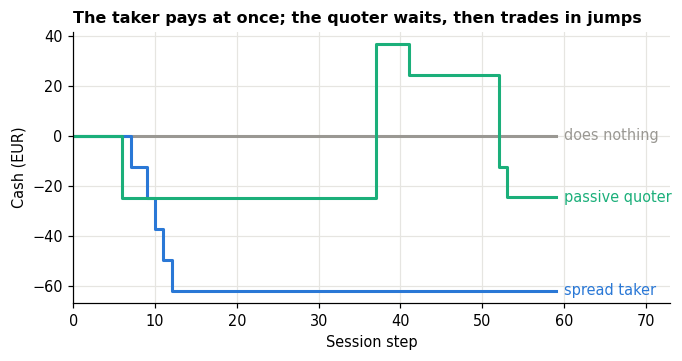

In [9]:
fig, ax = plt.subplots()
colours = {"does nothing": GREY, "spread taker": BUY, "passive quoter": THIRD}
for name, (_, cash, _) in results.items():
    steps = np.arange(len(cash))
    ax.step(steps, cash, where="post", color=colours[name], lw=2)
    ax.text(steps[-1] + 1, cash[-1], name, color=colours[name], va="center")
ax.set_xlim(0, steps[-1] + 14)
ax.set_xlabel("Session step")
ax.set_ylabel("Cash (EUR)")
ax.set_title("The taker pays at once; the quoter waits, then trades in jumps")
plt.show()

## 5. Pitfall: `agent_cash` is the result, not `compute_agent_pnl`

`compute_agent_pnl` settles a trade tape in integer price and quantity steps (ticks). Run over the
agent's own trade tape, it agrees with `agent_cash` on the three runs above:

In [10]:
for name, (state, _, _) in results.items():
    tape_pnl = float(compute_agent_pnl(state.agent_trades.reshape(-1, 6), AGENT_TRADER_ID))
    print(f"{name:<16} agent_cash {float(state.agent_cash[0]):+9.3f} EUR, compute_agent_pnl {tape_pnl:+9.3f} EUR")

does nothing     agent_cash    +0.000 EUR, compute_agent_pnl    +0.000 EUR
spread taker     agent_cash   -61.900 EUR, compute_agent_pnl   -61.900 EUR
passive quoter   agent_cash   -24.475 EUR, compute_agent_pnl   -24.475 EUR


It is not always so. Each step has a single row for the agent's resting orders that traded: it records the
net direction, the total quantity and the quantity-weighted average price, rounded to
a price tick. If, in one step, one of the agent's resting bids
*and* one of its resting asks both trade, a single row cannot hold a purchase and a sale, and the tape's
result is wrong ([Limitations](../docs/limitations.md#settlement-over-the-participants-trade-tape)).

The hand-made tape 2 builds exactly that case. The agent rests a bid at 49.50 at step 0 and an ask at
50.50 at step 1; in step 2, a tape sell at 49.50 and a tape buy at 50.50 trade against both.

In [11]:
state = session.reset(key).replace(tape_idx=jnp.int32(2))
plan = {0: AgentOrder.create(side=Side.BUY, price=49.5, quantity=1.0),
        1: AgentOrder.create(side=Side.SELL, price=50.5, quantity=1.0)}
done, step = False, 0
while not done:
    state, report, done = session.step(key, state, plan.get(step))
    done = bool(done)
    print(f"step {step}: resting orders traded {float(report.passive_qty_signed):+.1f} MW net, "
          f"cash change {float(report.cash_delta_eur):+.3f} EUR")
    step += 1

exact = float(state.agent_cash[0])
tape_pnl = float(compute_agent_pnl(state.agent_trades.reshape(-1, 6), AGENT_TRADER_ID))
print(f"position {float(state.agent_inventory[0]):+.1f} MW; agent_cash {exact:+.3f} EUR; "
      f"compute_agent_pnl {tape_pnl:+.3f} EUR")

step 0: resting orders traded +0.0 MW net, cash change +0.000 EUR
step 1: resting orders traded +0.0 MW net, cash change +0.000 EUR
step 2: resting orders traded +0.0 MW net, cash change +0.250 EUR
position +0.0 MW; agent_cash +0.250 EUR; compute_agent_pnl -25.000 EUR


The agent bought 1 MW at 49.50 and sold 1 MW at 50.50: it earned $(50.50 - 49.50) \cdot 1 \cdot 0.25 = 0.25$
EUR, which is what `agent_cash` says. The trade tape squeezed both trades into one row of 2 MW at their
average price of 50.00 EUR/MWh. The net quantity is zero, and such a row is recorded as a purchase, so
`compute_agent_pnl` reports $-2 \cdot 50 \cdot 0.25 = -25$ EUR.
Report `state.agent_cash`. Use `compute_agent_pnl` only as a cross-check: it is wrong on a step where
resting orders traded in both directions. It can also be slightly off on a step where resting orders
traded in one direction at several prices, because the row's average price is rounded to a tick.

## Recap

- An agent is a function from the market view (and its own state) to an `AgentOrder`; `AgentOrder.none()`
  means no order.
- Writing the decision with `jnp` operations, and the "trade or not" choice as the order's `active` flag,
  keeps an agent ready for a compiled loop.
- A trade is worth $V = p \cdot q \cdot d$ with $d = 0.25$ h; sales add $V$ to the cash, purchases subtract it.
- Compare agents on their cash *and* their position; report `state.agent_cash`, not `compute_agent_pnl`
  over the agent's trade tape.

## Exercises

1. **A taker that also sells.** Change the spread taker so that, when its position reaches 2 MW, it sells
   1 MW at the best bid instead of buying. Keep it free of Python `if` on values. *Hint:* choose the side
   and the price with `jnp.where`.
2. **A quoter that refreshes its quote.** The passive quoter never cancels, so old quotes pile up in the
   book. Make it cancel its previous quote before sending a new one. *Hint:* keep the `order_id` from the
   `FillReport`, and use `ContractBook.cancel_order` between steps, as in [T05](T05_session.ipynb).
3. **Another day.** Run the three agents on tape 1 and print the same table. Does the ranking change?
   *Hint:* `run(agent, tape_idx=1)`.

The solutions are in the collapsed cell at the end.

## Further reading

- [Sessions](../docs/sessions.md), section *Settlement*, and [Limitations](../docs/limitations.md).
- [The market model](../docs/market-model.md), section *Settlement and sign convention*.
- The evidence: [the market specification](../docs/omiecid/market-spec.md) ([§8](../docs/omiecid/market-spec.md#8-settlement-and-pnl), settlement) and [the certificate](../docs/omiecid/certificate.md) ([C12](../notebooks/certification/C12_settlement_cash_leg.ipynb) certifies the cash leg of every trade).
- Next: [T09 — Running many sessions fast](T09_scaling.ipynb) runs the spread taker inside a compiled loop.

## Solutions

In [12]:
# Solutions to the exercises (collapsed; expand to read).
from omiecid_simulator.omiecid.contract import Contract, ContractStatus
from omiecid_simulator.omiecid.contract_book import ContractBook


# 1. The side and the price are chosen with jnp.where, so the function stays traceable.
def round_trip_taker(tob, state, max_spread=0.15, sell_from=2.0, qty=1.0):
    narrow = tob.has_bid & tob.has_ask & (tob.p_ask - tob.p_bid < max_spread)
    selling = state.agent_inventory[0] >= sell_from
    side = jnp.where(selling, int(Side.SELL), int(Side.BUY))
    price = jnp.where(selling, tob.p_bid, tob.p_ask)
    return AgentOrder.create(side=side, price=price, quantity=qty,
                             exec_restriction=int(ExecRestriction.IOC))._replace(active=narrow)


st, cash, _ = run(round_trip_taker, tape_idx=0)
print(f"1. position {float(st.agent_inventory[0]):+.1f} MW, cash {cash[-1]:+.3f} EUR, trade rows {n_trades(st)}")

# 2. The cancel needs the book-level API, so it lives in the loop, next to the agent.
book = ContractBook(Contract(contract_id=0, delivery_start_minutes=120, delivery_end_minutes=135,
                             gct_minutes=60, status=ContractStatus.OPEN),
                    session.product_config, session.market_config)
st, done, last = session.reset(key).replace(tape_idx=jnp.int32(0)), False, None
while not done:
    order = passive_quoter(session.top_of_book(st), st)
    if bool(order.active) and last is not None:
        st = st.replace(book=book.cancel_order(st.book, *last))  # no effect if it already traded
    st, rep, done = session.step(key, st, order)
    done = bool(done)
    if bool(rep.submitted):
        last = (int(rep.order_id), int(order.side))
print(f"2. position {float(st.agent_inventory[0]):+.1f} MW, cash {float(st.agent_cash[0]):+.3f} EUR, "
      f"resting at gate closure: {len(book.get_agent_orders(st.book, AGENT_TRADER_ID))}")

# 3. The same table on tape 1.
for name, agent in AGENTS.items():
    st, cash, _ = run(agent, tape_idx=1)
    print(f"3. {name:<16}{float(st.agent_inventory[0]):>+6.1f} MW{cash[-1]:>+10.3f} EUR{n_trades(st):>4} trade rows")

1. position +1.0 MW, cash -12.625 EUR, trade rows 9


2. position +1.0 MW, cash -12.350 EUR, resting at gate closure: 1
3. does nothing      +0.0 MW    +0.000 EUR   0 trade rows


3. spread taker      +5.0 MW   -63.800 EUR   5 trade rows
3. passive quoter    +7.0 MW   -89.000 EUR   8 trade rows
